# Components of LangGraph

LangGraph is a framework for building stateful, multi-step AI workflows using graphs. The main components are:

### 1. State
The shared data that flows through the graph. It stores information that nodes read and update throughout the execution.

```python
class State(TypedDict):
    question: str
    answer: str
```

---

### 2. Nodes
Nodes are Python functions that perform a specific task. They receive the current state and return updates to the state.

```python
def generate_answer(state: State):
    return {"answer": "Hello!"}
```

---

### 3. Edges
Edges define the execution flow between nodes.

```python
graph.add_edge(START, "generate_answer")
graph.add_edge("generate_answer", END)
```

---

### 4. START
A special entry point that marks where graph execution begins.

```python
graph.add_edge(START, "first_node")
```

---

### 5. END
A special terminal node that marks where graph execution finishes.

```python
graph.add_edge("last_node", END)
```

---

### 6. StateGraph
The graph builder used to create workflows.

```python
graph = StateGraph(State)
```

---

### 7. Compilation
After defining nodes and edges, compile the graph into an executable workflow.

```python
workflow = graph.compile()
```

---

### 8. Execution
Run the compiled workflow by providing an initial state.

```python
result = workflow.invoke(initial_state)
```

---

## Workflow

```
Initial State
      │
      ▼
    START
      │
      ▼
    Node 1
      │
      ▼
    Node 2
      │
      ▼
     ...
      │
      ▼
     END
      │
      ▼
 Final State
```

### Summary
- **State** → Shared data.
- **Nodes** → Perform computations.
- **Edges** → Control execution order.
- **START** → Beginning of the graph.
- **END** → End of the graph.
- **StateGraph** → Builds the workflow.
- **compile()** → Creates an executable graph.
- **invoke()** → Executes the graph with an initial state.

In [9]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
from IPython.display import Image
load_dotenv()

True

In [3]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

In [4]:
# Creating a state 
class LLMState(TypedDict):
    question: str
    answer: str

In [5]:
def llm_qa(state: LLMState) -> LLMState:

    # extract the question from state
    question = state['question']

    # form a prompt
    prompt = f'Answer the following question {question}'

    # ask that question to the LLM
    answer = llm.invoke(prompt).content

    # update the answer in the state
    state['answer'] = answer

    return state

In [6]:
# create our graph
graph = StateGraph(LLMState)

# add nodes
graph.add_node('llm_qa', llm_qa)

# add edges
graph.add_edge(START, 'llm_qa')
graph.add_edge('llm_qa', END)

# compile
workflow = graph.compile()

In [7]:
# execute
intial_state = {'question': 'How far is moon from the earth?'}
final_state = workflow.invoke(intial_state)
print(final_state['answer'])

[{'type': 'text', 'text': 'The average distance from the Earth to the Moon is about **384,400 kilometers** (or about **238,855 miles**). \n\nBecause the Moon travels in an elliptical (oval-shaped) orbit rather than a perfect circle, this distance constantly changes:\n* **Perigee (Closest point):** About 363,300 km (225,600 miles)\n* **Apogee (Farthest point):** About 405,500 km (251,980 miles) \n\nTo put that distance into perspective, you could fit all the planets in our solar system side-by-side in the space between the Earth and the Moon!', 'extras': {'signature': 'El8KXQFpFH0TopgoxdgY7xQhsFLk5UZTF9M7I+PRsAmP2AAEju9T50SaDfn64kMUFFXQLewZ1ayyCNFlOZAYcdpdG2QCeO6tD+zWvXLZScX5Mqu1vGdag6K2emjbpJ/Qdg=='}}]


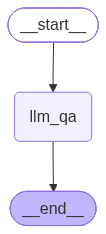

In [10]:
Image(workflow.get_graph().draw_mermaid_png())

In [11]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [12]:
def create_outline(state: BlogState) -> BlogState:
    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = llm.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [ ]:
def create_blog(state: BlogState) -> BlogState:
    
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = llm.invoke(prompt).content

    state['content'] = content

    return state

In [14]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

In [15]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': [{'type': 'text', 'text': 'Here is a detailed, SEO-friendly outline for a blog post on the **"Rise of AI in India."** \n\n---\n\n# **Blog Title Options:**\n*   *The AI Revolution in India: How Artificial Intelligence is Shaping the Future*\n*   *From Silicon Valley to Silicon subcontinent: The Rapid Rise of AI in India*\n*   *Bharat 2.0: Understanding the AI Boom Transforming India*\n\n---\n\n## **I. Introduction**\n*   **The Hook:** Start with a relatable scenario (e.g., interacting with an AI chatbot in regional language, traffic management, or UPI transactions powered by backend AI).\n*   **The Big Picture:** Briefly introduce India’s rapid digital transformation, moving from an IT outsourcing hub to a global AI innovation powerhouse.\n*   **Thesis Statement:** Driven by massive data, a young tech-savvy population, and proactive government policies, India is not just adopting AI—it is creating solutions tailored for the next billion users.

In [16]:
print(final_state['outline'])

[{'type': 'text', 'text': 'Here is a detailed, SEO-friendly outline for a blog post on the **"Rise of AI in India."** \n\n---\n\n# **Blog Title Options:**\n*   *The AI Revolution in India: How Artificial Intelligence is Shaping the Future*\n*   *From Silicon Valley to Silicon subcontinent: The Rapid Rise of AI in India*\n*   *Bharat 2.0: Understanding the AI Boom Transforming India*\n\n---\n\n## **I. Introduction**\n*   **The Hook:** Start with a relatable scenario (e.g., interacting with an AI chatbot in regional language, traffic management, or UPI transactions powered by backend AI).\n*   **The Big Picture:** Briefly introduce India’s rapid digital transformation, moving from an IT outsourcing hub to a global AI innovation powerhouse.\n*   **Thesis Statement:** Driven by massive data, a young tech-savvy population, and proactive government policies, India is not just adopting AI—it is creating solutions tailored for the next billion users.\n\n## **II. The Catalyst: Why is AI Booming

In [17]:
print(final_state['content'])

[{'type': 'text', 'text': '# **Bharat 2.0: Understanding the AI Boom Transforming India**\n\nPicture this: A farmer in rural Madhya Pradesh pulls out his smartphone, speaks a query in fluent Hindi into an agricultural app, and receives instant, AI-driven advice on how to treat a crop infestation. Meanwhile, in Mumbai, millions of financial transactions are being scanned for fraud in milliseconds by backend machine learning algorithms. \n\nThis isn\'t a sci-fi movie—this is everyday life in modern India. \n\nFor decades, India was celebrated as the back-office and IT outsourcing capital of the world. Today, the script has flipped. Driven by massive data, a young tech-savvy population, and proactive government policies, India is not just adopting artificial intelligence—it is creating solutions tailored for the next billion users. Welcome to the rise of AI on the Silicon Subcontinent.\n\n---\n\n## **II. The Catalyst: Why is AI Booming in India Right Now?**\n\nThe unprecedented surge of A